Name: Emily Savoie

Labpartner(s)

In [ ]:
#import statements go here


# Class 12.1

# Warmups 12.1

Note: finish this for lab if you don't finish in class.

Log into the Supermike III LSU HPC using ssh (in the terminal). See the help docs we went over last time. 

**W.1.** Investigate each of the following basic unix/linux commands:
- ls
- pwd
- cd
- scp
- scp -r

What do each of these do? If you forgot, you can type "man ls", etc. to see the documentation.

- ls = list all files and directories in current location
- pwd = shows the complete path for your current working directory
- cd = swaps to a different directory based on provided path
- scp = secure method for transferring files and directories between systems using SSH
- scp -r = secure method to copy an entire directory with all its contents

**W.2** Look up the LSU HPC documentation for /work and /home, what is the difference? What are the quotas for each? How long will files last? Are they backed up?

/work is a shared storage space between all users for job input and output. The files are never backed up in /work, they have a lifetime of 60 days with no activity. There is an unlimited quota for /work.  

/home is a storage space provided to a user. Files in /home are backed up periodically. As long as a user has an active account, the files will remain. There is a 10 GB quota on /home.

# Lecture 12.1

### Agenda:


Some useful things to do with a timeseries
- datetime objects
- basic line fitting
- moving averages
- detrending

#### Datetime Objects in python and pandas

Python has a wonderful feature called datetime objects. These are super-useful if you are dealing with any data that has a timestamp. They are a bit tricky to get used to, but worth the effort, and the alternatives are usually much more painful (trust me on this one). 

Documentation: 
- https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html
- https://docs.python.org/3/library/datetime.html

There is a lot you can do with these. Here we will just cover the basics. Dig in to the documentation if you need something specfic.

In [54]:
from datetime import datetime, timedelta
import pandas as pd

#### Defining a specfic date

In [55]:
date1 = datetime(1996,1,1) 

In [3]:
# this is a datetime object
date1

datetime.datetime(1996, 1, 1, 0, 0)

In [4]:
# print out the date
print(date1)

1996-01-01 00:00:00


In [5]:
# you can also format the date as a string however you like (useful for plots)
date1.strftime("%m/%d/%Y")

'01/01/1996'

In [56]:
# defining a date with hours, minutes and seconds
date2 = datetime(1996,1,1, 13, 34, 6) # note using 24 clock (miltary time) here

In [7]:
print(date2)

1996-01-01 13:34:06


In [8]:
#what is going to happen here?
date2.strftime("%m-%d-%Y")

'01-01-1996'

In [57]:
date1.today() #somehow it knows what timezone I am (probably from my computer)

datetime.datetime(2026, 11, 11, 10, 15, 44, 877364)

#### If we want to increment the date we can use timedelta

In [58]:
date1 = date1 + timedelta(days=1)
print(date1)

1996-01-02 00:00:00


In [11]:
date1 = date1 + timedelta(minutes = 2, seconds=1)
print(date1)

1996-01-02 00:02:01


In [12]:
# you can also do things like add fractional days
date1 = date1 + timedelta(days=1.5)
print(date1)

1996-01-03 12:02:01


We can find the time difference between two dates

In [13]:
timediff = date2-date1
timediff

datetime.timedelta(days=-2, seconds=5525)

#### We can also define timeseries using pandas 

In [14]:
pd.date_range?

Signature:
pd.date_range(
    start=None,
    end=None,
    periods=None,
    freq=None,
    tz=None,
    normalize: 'bool' = False,
    name: 'Hashable | None' = None,
    inclusive: 'IntervalClosedType' = 'both',
    *,
    unit: 'TimeUnit | None' = None,
    **kwargs,
) -> 'DatetimeIndex'
Docstring:
Return a fixed frequency DatetimeIndex.

Returns the range of equally spaced time points (where the difference between any
two adjacent points is specified by the given frequency) such that they fall in the
range `[start, end]` , where the first one and the last one are, resp., the first
and last time points in that range that fall on the boundary of ``freq`` (if given
as a frequency string) or that are valid for ``freq`` (if given as a
:class:`pandas.tseries.offsets.DateOffset`). If ``freq`` is positive, the points
satisfy `start <[=] x <[=] end`, and if ``freq`` is negative, the points satisfy
`end <[=] x <[=] start`. (If exactly one of ``start``, ``end``, or ``freq`` is *not*
specifie

In [15]:
# note the default is daily
my_daterange = pd.date_range(start='1/1/2018', end='1/08/2018')

In [16]:
my_daterange

DatetimeIndex(['2018-01-01', '2018-01-02', '2018-01-03', '2018-01-04',
               '2018-01-05', '2018-01-06', '2018-01-07', '2018-01-08'],
              dtype='datetime64[us]', freq='D')

In [17]:
# this can be indexed like any array
my_daterange[-1]
# note the result is a timestamp, which is similar to a datetime object, but not exactly

Timestamp('2018-01-08 00:00:00')

In [18]:
print(my_daterange[1])

2018-01-02 00:00:00


In [19]:
# you can convert a datetime to a timestamp
pd.Timestamp(datetime(2012, 5, 1))

Timestamp('2012-05-01 00:00:00')

In [20]:
# we can also specfiy the frequency
my_daterange2 = pd.date_range(start='1/1/2018',end = '12/1/2021', freq='ME')
my_daterange2

DatetimeIndex(['2018-01-31', '2018-02-28', '2018-03-31', '2018-04-30',
               '2018-05-31', '2018-06-30', '2018-07-31', '2018-08-31',
               '2018-09-30', '2018-10-31', '2018-11-30', '2018-12-31',
               '2019-01-31', '2019-02-28', '2019-03-31', '2019-04-30',
               '2019-05-31', '2019-06-30', '2019-07-31', '2019-08-31',
               '2019-09-30', '2019-10-31', '2019-11-30', '2019-12-31',
               '2020-01-31', '2020-02-29', '2020-03-31', '2020-04-30',
               '2020-05-31', '2020-06-30', '2020-07-31', '2020-08-31',
               '2020-09-30', '2020-10-31', '2020-11-30', '2020-12-31',
               '2021-01-31', '2021-02-28', '2021-03-31', '2021-04-30',
               '2021-05-31', '2021-06-30', '2021-07-31', '2021-08-31',
               '2021-09-30', '2021-10-31', '2021-11-30'],
              dtype='datetime64[us]', freq='ME')

See the documentation for lots more functionality

### Working with timeseries data: global sea surface temperature (SST)

We are going to be using some data from the EPA website here: https://www.ncei.noaa.gov/products/extended-reconstructed-sst 

This is globally averaged Extended Reconstructed Sea Surface Temperature (ERSST)v.4 from NOAA, which combines satilite, ship and other in situ (in place, i.e. in the water) data. If you follow the links on the above you can get the gridded (i.e. map) product in netcdf format for the latest product (v.5). We are just going to play around with the globally averaged data

In [2]:
sst= pd.read_csv('https://www.epa.gov/system/files/other-files/2024-06/sea-surface-temp_fig-1.csv')

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xb0 in position 247: invalid start byte

That didn't work. I did some googling to figure out why and added an encoding specification: 

In [12]:
sst= pd.read_csv('https://www.epa.gov/system/files/other-files/2024-06/sea-surface-temp_fig-1.csv',
                encoding = 'latin1')

In [13]:
sst

,"Figure 1. Average Global Sea Surface Temperature, 1880-2023",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,Source: EPA's Climate Change Indicators in the...,NaN,NaN,NaN
1,"Data source: NOAA, 2024",NaN,NaN,NaN
2,Web update: June 2024,NaN,NaN,NaN
3,Units: temperature anomaly (°F),NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
...,...,...,...,...
145,2019,0.878,0.822,0.935
146,2020,0.846,0.804,0.888
147,2021,0.668,0.622,0.714
148,2022,0.743,0.701,0.786


In [14]:
sst.head(10)

,"Figure 1. Average Global Sea Surface Temperature, 1880-2023",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,Source: EPA's Climate Change Indicators in the...,NaN,NaN,NaN
1,"Data source: NOAA, 2024",NaN,NaN,NaN
2,Web update: June 2024,NaN,NaN,NaN
3,Units: temperature anomaly (°F),NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
5,Year,Annual anomaly,Lower 95% confidence interval,Upper 95% confidence interval
6,1880,-0.418,-0.626,-0.21
7,1881,-0.33,-0.531,-0.128
8,1882,-0.344,-0.541,-0.146
9,1883,-0.459,-0.653,-0.265


I want this to be indexed by year, I don't want the first column, and I want to specify the header of all the metadata so it's doesn't mess up my analysis:

In [16]:
sst= pd.read_csv('https://www.epa.gov/sites/production/files/2016-08/sea-surface-temp_fig-1.csv',
                 index_col = 0, # this makes the year the index
                  header = 6, # row with column header labels; based on line by line counts rather than row index
                 #skiprows = [0,1,2,3,4,5], # this works too, need to skip all the comments
                 encoding ='latin1' # had to do this to get it to work, thanks stack exchange
                )

In [18]:
sst

,Annual anomaly,Lower 95% confidence interval,Upper 95% confidence interval
Year,,,
1880,-0.470009,-0.672646,-0.267371
1881,-0.356879,-0.560588,-0.153169
1882,-0.372661,-0.575728,-0.169594
1883,-0.448443,-0.650804,-0.246082
1884,-0.589754,-0.790478,-0.389030
...,...,...,...
2011,0.428674,0.133289,0.724058
2012,0.528696,0.232869,0.824523
2013,0.584674,0.289227,0.880122


<Axes: xlabel='Year'>

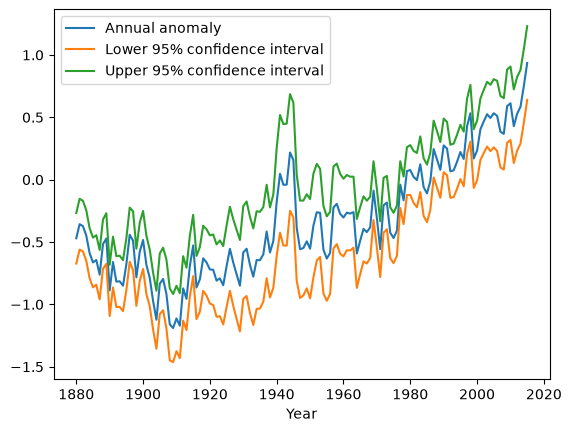

In [19]:
sst.plot()

I'm going to reset my universal plotting specs (I usually do this at the top with my import statements) to make the plot nice

In [20]:
#Set plotting formats
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = [13.0, 6.0]
mpl.rcParams['font.size'] = 16
mpl.rcParams['legend.fontsize'] = 'medium'
mpl.rcParams['figure.titlesize'] = 'medium'
mpl.rcParams['lines.linewidth'] = 2.0

<Axes: xlabel='Year'>

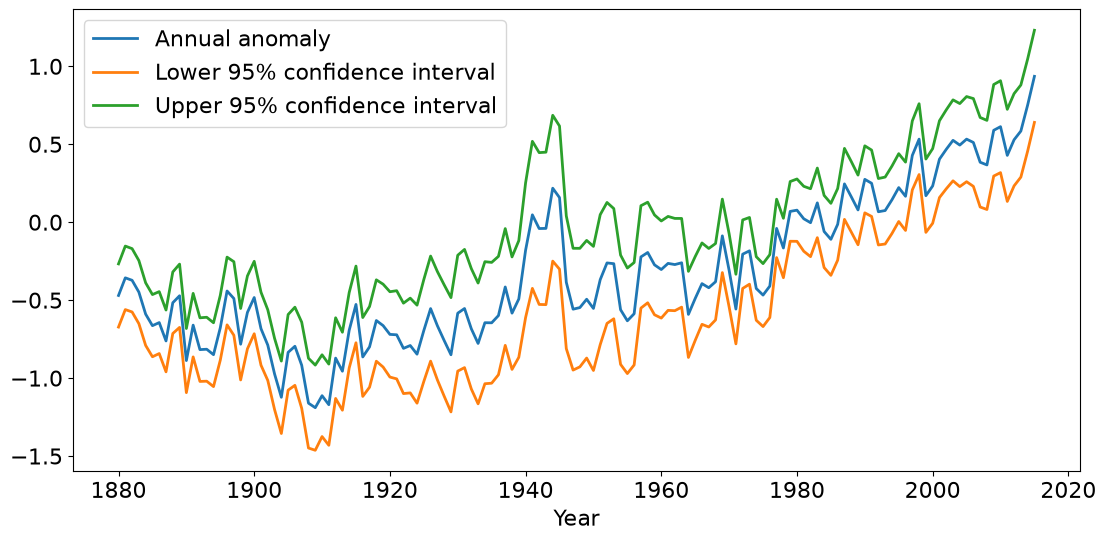

In [21]:
sst.plot()

1850 is usually considered the beginning of the industrial revolution, so before human affected climate by burning fossil fuels (but we did major land use changes and had impacts on many species' extinctions)

There is a definate trend in the data, with a big excursion in the 1940s

Let's ask some research questions. We will start these in lecture and you will finish them in lab:
- What is the trend in this data, that is how fast is SST increasing with time? 
- If we choose a different window for the trend analysis, how does this affect the answer?
- What causes all the interannual variablilty? If we detrend the data how does it look? Can we compare this with climate variabiltiy indices?
- What happened in the 1940s?

see: https://www.newscientist.com/article/dn11639-climate-myths-the-cooling-after-1940-shows-co2-does-not-cause-warming/

I am much more comfortable doing data analysis in xarray so I'm converting the pandas dataframe to an xarray dataset

In [22]:
import xarray as xr

In [23]:
sst_ds = sst.to_xarray()

In [24]:
sst_ds

<xarray.Dataset> Size: 4kB
Dimensions:                        (Year: 136)
Coordinates:
  * Year                           (Year) int64 1kB 1880 1881 1882 ... 2014 2015
Data variables:
    Annual anomaly                 (Year) float64 1kB -0.47 -0.3569 ... 0.9356
    Lower 95% confidence interval  (Year) float64 1kB -0.6726 -0.5606 ... 0.6401
    Upper 95% confidence interval  (Year) float64 1kB -0.2674 -0.1532 ... 1.231

If we want, we can add a pandas date range to this timeseries and use this for plotting. Not super needed here because it's annual, but would be useful if it was monthly or daily.

In [25]:
ssha_dates = pd.date_range(start = '1880', end = '2015', freq='YE')

In [26]:
ssha_dates

DatetimeIndex(['1880-12-31', '1881-12-31', '1882-12-31', '1883-12-31',
               '1884-12-31', '1885-12-31', '1886-12-31', '1887-12-31',
               '1888-12-31', '1889-12-31',
               ...
               '2005-12-31', '2006-12-31', '2007-12-31', '2008-12-31',
               '2009-12-31', '2010-12-31', '2011-12-31', '2012-12-31',
               '2013-12-31', '2014-12-31'],
              dtype='datetime64[us]', length=135, freq='YE-DEC')

In [27]:
# let's just work with the annual anomaly

sst_ds["Annual anomaly"] # note a lot of the syntax in xarray is similar to pandas

<xarray.DataArray 'Annual anomaly' (Year: 136)> Size: 1kB
array([-0.4700088, -0.3568788, -0.3726612, -0.448443 , -0.5897538,
       -0.6636546, -0.6439392, -0.7616232, -0.5166342, -0.4717926,
       -0.8875836, -0.6603264, -0.8173098, -0.8148276, -0.84978  ,
       -0.6772536, -0.4412844, -0.4894326, -0.78255  , -0.578736 ,
       -0.4833054, -0.6831072, -0.7883226, -0.9732618, -1.123038 ,
       -0.8347986, -0.795843 , -0.917685 , -1.160703 , -1.189773 ,
       -1.112769 , -1.1706066, -0.8718498, -0.9557658, -0.6931926,
       -0.5274864, -0.8644752, -0.7996338, -0.6306858, -0.6633414,
       -0.7196544, -0.7222464, -0.8093034, -0.7910208, -0.8465382,
       -0.6946722, -0.554238 , -0.6640884, -0.7589772, -0.8502282,
       -0.5835816, -0.5537106, -0.683568 , -0.7777674, -0.6447312,
       -0.6452784, -0.5988258, -0.4155462, -0.5834772, -0.4924098,
       -0.1797678,  0.0471582, -0.0406296, -0.039807 ,  0.2180826,
        0.157752 , -0.3853548, -0.5579568, -0.5477346, -0.4941792,
       -0.5531796, -0.368496 , -0.2612952, -0.2661372, -0.5613282,
       -0.632412 , -0.5871312, -0.2226618, -0.1943208, -0.2735424,
       -0.3035772, -0.2642508, -0.2717028, -0.260397 , -0.5913306,
       -0.489249 , -0.39411  , -0.4203576, -0.38187  , -0.0876366,
       -0.3086334, -0.5571756, -0.2051676, -0.1836738, -0.4251924,
       -0.4675428, -0.4096278, -0.0397692, -0.165393 ,  0.0692586,
        0.0771966,  0.0219924, -0.0032202,  0.1239354, -0.0596304,
       -0.109917 , -0.0137916,  0.2456388,  0.1634436,  0.0785898,
        0.274842 ,  0.2497932,  0.0669942,  0.0748224,  0.1436454,
        0.2219328,  0.1661922,  0.428193 ,  0.5327244,  0.1698606,
        0.2325024,  0.4042188,  0.4671414,  0.5250798,  0.4946364,
        0.5327874,  0.5114556,  0.3846042,  0.3673116,  0.5894424,
        0.6127182,  0.4286736,  0.528696 ,  0.5846742,  0.7512552,
        0.935577 ])
Coordinates:
  * Year     (Year) int64 1kB 1880 1881 1882 1883 1884 ... 2012 2013 2014 2015

#### Let's do a linear fit of the whole timeseries

Linear regression is simply fitting a line to some data, assuming that the data is on a straight line with the equation y=**m**x+**b**, where x and y are the independent and dependent data, **m** is the slope, and **b** is the intercept. Linear regression finds m and b by minimizing the distance of all the data points to a line, getting the best fit, using calculus. See:

https://plainenglish.io/blog/linear-regression-for-dummies

https://en.wikipedia.org/wiki/Linear_regression


In [28]:
from scipy import stats

In [29]:
stats.linregress?

Signature:
stats.linregress(
    x,
    y,
    alternative='two-sided',
    *,
    axis=0,
    nan_policy='propagate',
    keepdims=False,
)
Docstring:
Calculate a linear least-squares regression for two sets of measurements.

Parameters
----------
x, y : array_like
    Two sets of measurements.  Both arrays should have the same length N.
alternative : {'two-sided', 'less', 'greater'}, optional
    Defines the alternative hypothesis. Default is 'two-sided'.
    The following options are available:
    
    * 'two-sided': the slope of the regression line is nonzero
    * 'less': the slope of the regression line is less than zero
    * 'greater':  the slope of the regression line is greater than zero
    
    .. versionadded:: 1.7.0
axis : int or None, default: 0
    If an int, the axis of the input along which to compute the statistic.
    The statistic of each axis-slice (e.g. row) of the input will appear in a
    corresponding element of the output.
    If ``None``, the input will be

In [30]:
# the syntax for this function is x,y, so time, ssta
ssta_trend_entire = stats.linregress(sst_ds.Year, sst_ds["Annual anomaly"])

In [31]:
ssta_trend_entire

LinregressResult(slope=np.float64(0.010013503267496778), intercept=np.float64(-19.822035179626447), rvalue=np.float64(0.836269454413966), pvalue=np.float64(8.796275453012706e-37), stderr=np.float64(0.0005671794277975707), intercept_stderr=np.float64(1.1048063455210597))

In [32]:
ssta_trend_entire.slope

np.float64(0.010013503267496778)

The value I am interested in is the slope, what is this? What are the units?
- Rate that temperature is increasing (degrees F/Year)

Let's plot the line to see the fit. The equation is y = mx + b, where m is the slope and b is the intercept, what are x and y in this case?
- x is time
- y is temprature

In [33]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'SSTA ($\\degree$F)')

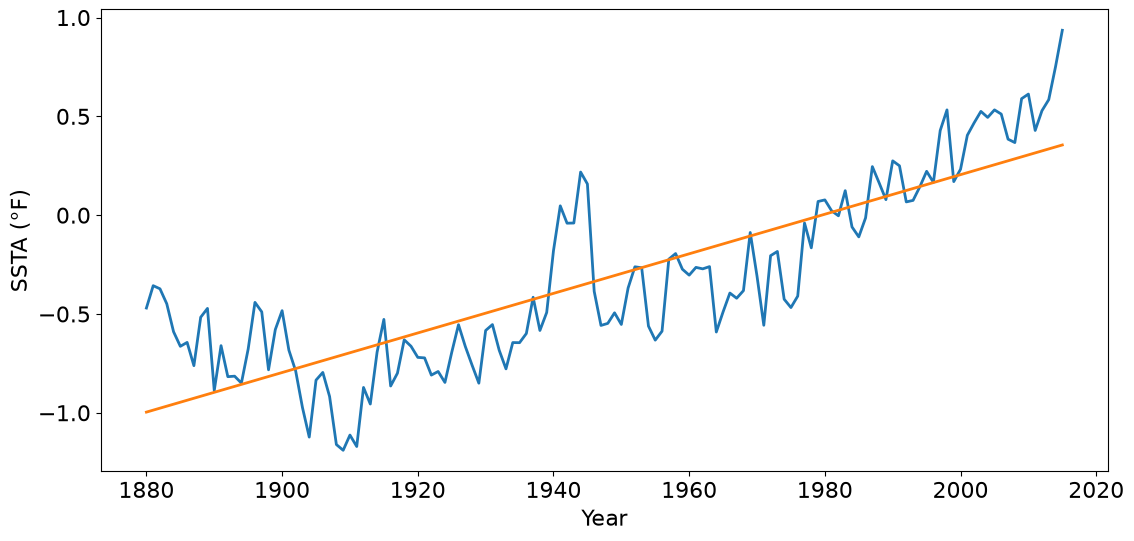

In [34]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"])

# plot the line
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept)

plt.xlabel('Year')
plt.ylabel('SSTA ($\degree$F)')

How good of a fit is this for the last few decades?
It's not so good, the trend is bigger, steeper

#### Let's do a linear fit for the last few decades and see what we get.

How do we access the later data?

In [35]:
sst_ds.Year[100:]

<xarray.DataArray 'Year' (Year: 36)> Size: 288B
[36 values with dtype=int64]
Coordinates:
  * Year     (Year) int64 288B 1980 1981 1982 1983 1984 ... 2012 2013 2014 2015

In [36]:
sst_ds["Annual anomaly"][100:]

<xarray.DataArray 'Annual anomaly' (Year: 36)> Size: 288B
array([ 0.0771966,  0.0219924, -0.0032202,  0.1239354, -0.0596304,
       -0.109917 , -0.0137916,  0.2456388,  0.1634436,  0.0785898,
        0.274842 ,  0.2497932,  0.0669942,  0.0748224,  0.1436454,
        0.2219328,  0.1661922,  0.428193 ,  0.5327244,  0.1698606,
        0.2325024,  0.4042188,  0.4671414,  0.5250798,  0.4946364,
        0.5327874,  0.5114556,  0.3846042,  0.3673116,  0.5894424,
        0.6127182,  0.4286736,  0.528696 ,  0.5846742,  0.7512552,
        0.935577 ])
Coordinates:
  * Year     (Year) int64 288B 1980 1981 1982 1983 1984 ... 2012 2013 2014 2015

In [37]:
# the syntax for this function is x,y, so time, ssta
ssta_trend_1980_on = stats.linregress(sst_ds.Year[100:], sst_ds["Annual anomaly"][100:])

In [38]:
ssta_trend_1980_on

LinregressResult(slope=np.float64(0.020711260308880312), intercept=np.float64(-41.05951991698843), rvalue=np.float64(0.8829830021529422), pvalue=np.float64(1.0383113887943913e-12), stderr=np.float64(0.0018882626420977902), intercept_stderr=np.float64(3.7718556347573653))

In [39]:
ssta_trend_1980_on.slope # 0.02 F/ year. 0.2 F /10 years

np.float64(0.020711260308880312)

Text(0, 0.5, 'SSTA ($\\degree$F)')

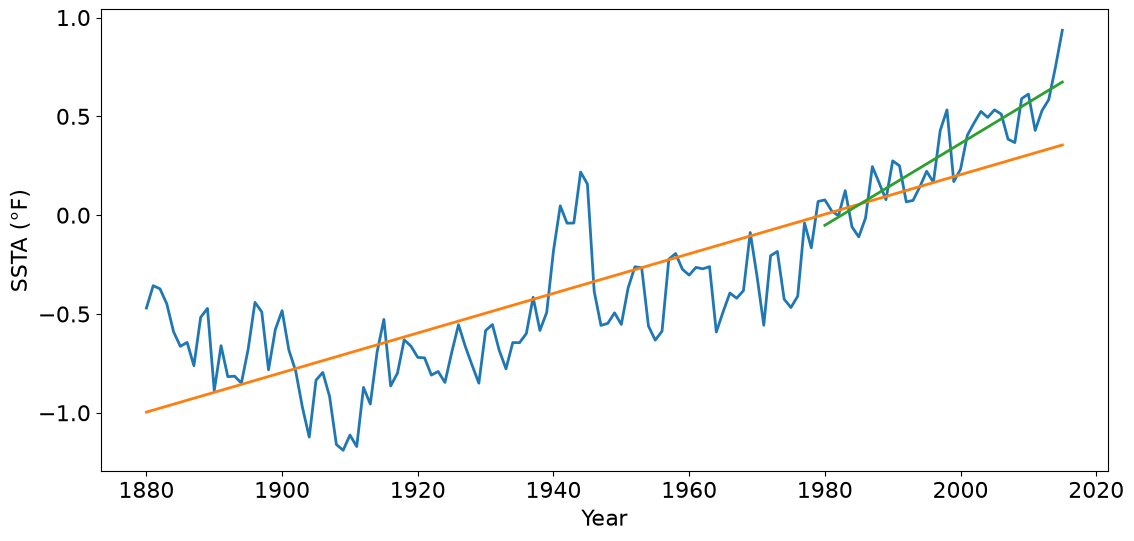

In [40]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"])
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept)
plt.plot(sst_ds.Year[100:], ssta_trend_1980_on.slope*sst_ds.Year[100:] + ssta_trend_1980_on.intercept)
plt.xlabel('Year')
plt.ylabel('SSTA ($\degree$F)')

#### Detrending the data
Let's say we were interested in the variability outside of the trend. How do we detrend the data?

In [ ]:
# First I am going to make the line, as I plotted before
trend_entire = ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept

In [42]:
trend_entire

<xarray.DataArray 'Year' (Year: 136)> Size: 1kB
array([-0.99664904, -0.98663553, -0.97662203, -0.96660853, -0.95659502,
       -0.94658152, -0.93656802, -0.92655451, -0.91654101, -0.90652751,
       -0.896514  , -0.8865005 , -0.876487  , -0.86647349, -0.85645999,
       -0.84644649, -0.83643298, -0.82641948, -0.81640598, -0.80639247,
       -0.79637897, -0.78636547, -0.77635196, -0.76633846, -0.75632496,
       -0.74631146, -0.73629795, -0.72628445, -0.71627095, -0.70625744,
       -0.69624394, -0.68623044, -0.67621693, -0.66620343, -0.65618993,
       -0.64617642, -0.63616292, -0.62614942, -0.61613591, -0.60612241,
       -0.59610891, -0.5860954 , -0.5760819 , -0.5660684 , -0.55605489,
       -0.54604139, -0.53602789, -0.52601438, -0.51600088, -0.50598738,
       -0.49597387, -0.48596037, -0.47594687, -0.46593336, -0.45591986,
       -0.44590636, -0.43589285, -0.42587935, -0.41586585, -0.40585234,
       -0.39583884, -0.38582534, -0.37581183, -0.36579833, -0.35578483,
       -0.34577132, -0.33575782, -0.32574432, -0.31573081, -0.30571731,
       -0.29570381, -0.2856903 , -0.2756768 , -0.2656633 , -0.25564979,
       -0.24563629, -0.23562279, -0.22560929, -0.21559578, -0.20558228,
       -0.19556878, -0.18555527, -0.17554177, -0.16552827, -0.15551476,
       -0.14550126, -0.13548776, -0.12547425, -0.11546075, -0.10544725,
       -0.09543374, -0.08542024, -0.07540674, -0.06539323, -0.05537973,
       -0.04536623, -0.03535272, -0.02533922, -0.01532572, -0.00531221,
        0.00470129,  0.01471479,  0.0247283 ,  0.0347418 ,  0.0447553 ,
        0.05476881,  0.06478231,  0.07479581,  0.08480932,  0.09482282,
        0.10483632,  0.11484983,  0.12486333,  0.13487683,  0.14489034,
        0.15490384,  0.16491734,  0.17493085,  0.18494435,  0.19495785,
        0.20497136,  0.21498486,  0.22499836,  0.23501187,  0.24502537,
        0.25503887,  0.26505237,  0.27506588,  0.28507938,  0.29509288,
        0.30510639,  0.31511989,  0.32513339,  0.3351469 ,  0.3451604 ,
        0.3551739 ])
Coordinates:
  * Year     (Year) int64 1kB 1880 1881 1882 1883 1884 ... 2012 2013 2014 2015

In [43]:
# Then I will subtract the trend, the line
sst_detrended = sst_ds["Annual anomaly"] - trend_entire

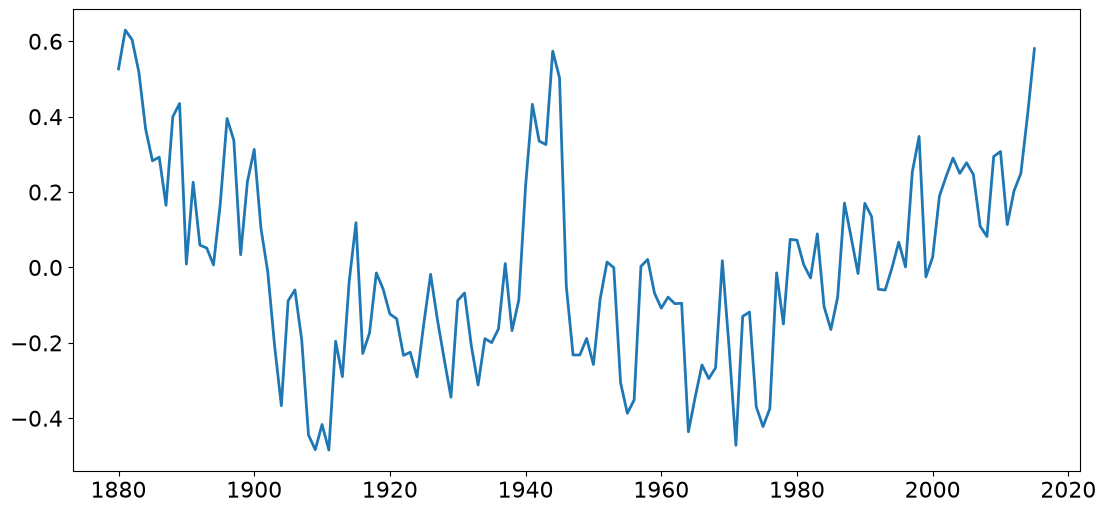

In [44]:
plt.plot(sst_ds.Year, sst_detrended)

#### Creating a moving average, i.e. filtering or smoothing.
Let's say we wanted to smooth the data to remove some of the variability, how would we do this?

I want to do a three year running mean, so for each datapoint, average the year before, the current year and the year after and save that to the current year as the new data.

if i is my current year index

(data[j+1] + data [j] + data [j-1])/3 to average the three years of data

Going to have to start at the second year, since I don't have a previous year


pseudo code:

create an array to save the new data in

Loop through all the years
 take a mean of the current, previous and next years, save to some new arrray


In [45]:
import numpy as np

In [46]:
sst_ds["Annual anomaly"].shape

(136,)

In [47]:
# initialize my array
ssta_filtered = np.zeros(136)

In [48]:
for i in range(134): # loop through all the years, skip the last index
    #print(i+1) #skip the first index
    ssta_filtered[i+1] = (sst_ds["Annual anomaly"][i] + sst_ds["Annual anomaly"][i+1] + sst_ds["Annual anomaly"][i+2])/3


In [49]:
ssta_filtered

array([ 0.       , -0.3998496, -0.392661 , -0.470286 , -0.5672838,
       -0.6324492, -0.689739 , -0.6407322, -0.58335  , -0.6253368,
       -0.6732342, -0.7884066, -0.7641546, -0.8273058, -0.7806204,
       -0.656106 , -0.5359902, -0.571089 , -0.6169062, -0.6148638,
       -0.5817162, -0.6515784, -0.8148972, -0.9615408, -0.9770328,
       -0.9178932, -0.8494422, -0.958077 , -1.089387 , -1.154415 ,
       -1.1577162, -1.0517418, -0.9994074, -0.8402694, -0.7254816,
       -0.6950514, -0.7305318, -0.7649316, -0.697887 , -0.6712272,
       -0.7017474, -0.7504014, -0.7741902, -0.8156208, -0.7774104,
       -0.6984828, -0.6376662, -0.6591012, -0.7577646, -0.730929 ,
       -0.6625068, -0.6069534, -0.671682 , -0.7020222, -0.689259 ,
       -0.6296118, -0.5532168, -0.5326164, -0.4971444, -0.4185516,
       -0.2083398, -0.0577464, -0.0110928,  0.045882 ,  0.1120092,
       -0.0031734, -0.2618532, -0.4970154, -0.5332902, -0.5316978,
       -0.4719516, -0.3943236, -0.2986428, -0.3629202, -0.4866

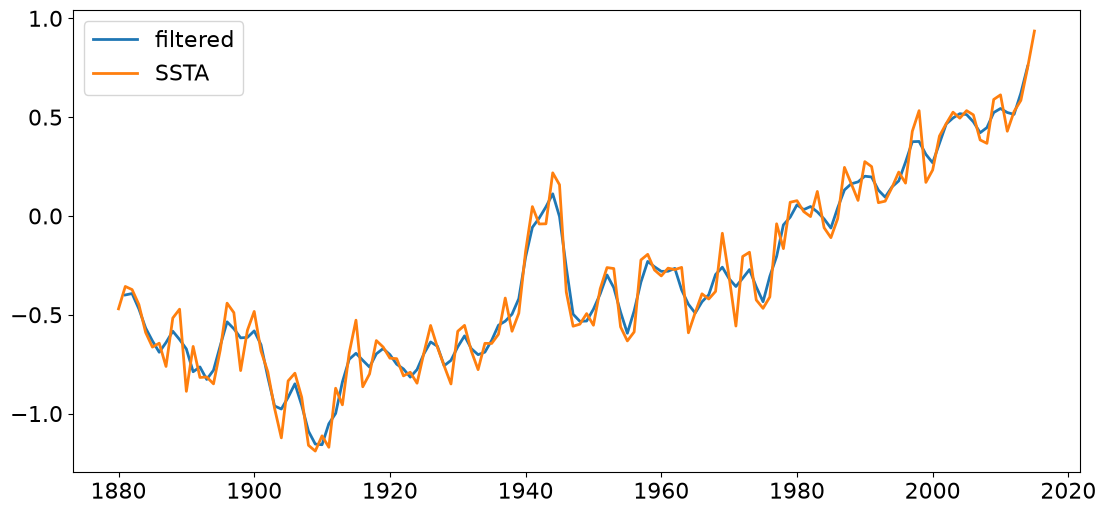

In [50]:
plt.plot(sst_ds.Year[1:-1],ssta_filtered[1:-1], label = "filtered")
plt.plot(sst_ds.Year,sst_ds["Annual anomaly"], label = 'SSTA')
plt.legend()

# Lab 12.1

**E.1** Define a datetime object that is your birthday. Increment this date using timedelta by a) ten weeks, b) five minutes, c) two years (tricky!) Hint: see help(timedelta)

In [66]:
birthday = datetime(1995, 10, 16)
print(birthday)

1995-10-16 00:00:00


In [67]:
birthday1 = birthday + timedelta(weeks = 10)
print(birthday1)

1995-12-25 00:00:00


In [69]:
birthday2 = birthday + timedelta(minutes = 5)
print(birthday2)

1995-10-16 00:05:00


In [70]:
birthday3 = birthday + timedelta(days = 731) # 1996 was a leap year so added an extra day
print(birthday3)

1997-10-16 00:00:00


**E.2** Define a daterange for your birthday every year of your life

In [73]:
annual_birthday = pd.date_range(start = '10/16/1995', end = '10/16/2026', freq = pd.DateOffset(years = 1))
annual_birthday

DatetimeIndex(['1995-10-16', '1996-10-16', '1997-10-16', '1998-10-16',
               '1999-10-16', '2000-10-16', '2001-10-16', '2002-10-16',
               '2003-10-16', '2004-10-16', '2005-10-16', '2006-10-16',
               '2007-10-16', '2008-10-16', '2009-10-16', '2010-10-16',
               '2011-10-16', '2012-10-16', '2013-10-16', '2014-10-16',
               '2015-10-16', '2016-10-16', '2017-10-16', '2018-10-16',
               '2019-10-16', '2020-10-16', '2021-10-16', '2022-10-16',
               '2023-10-16', '2024-10-16', '2025-10-16', '2026-10-16'],
              dtype='datetime64[us]', freq='<DateOffset: years=1>')

**E.3** Print all your birthdays out as month, day, year (no minutes, etc)

In [74]:
annual_birthday.strftime('%m/%d/%Y')

Index(['10/16/1995', '10/16/1996', '10/16/1997', '10/16/1998', '10/16/1999',
       '10/16/2000', '10/16/2001', '10/16/2002', '10/16/2003', '10/16/2004',
       '10/16/2005', '10/16/2006', '10/16/2007', '10/16/2008', '10/16/2009',
       '10/16/2010', '10/16/2011', '10/16/2012', '10/16/2013', '10/16/2014',
       '10/16/2015', '10/16/2016', '10/16/2017', '10/16/2018', '10/16/2019',
       '10/16/2020', '10/16/2021', '10/16/2022', '10/16/2023', '10/16/2024',
       '10/16/2025', '10/16/2026'],
      dtype='str')

**E.4** Do a linear fit of the SSTA data from 1940 to 1970. What trend do you get? How confident are you in this result? How does it compare to the trends we did in lecture (use quantitative data to explain).

The slope is -0.008 $\degree F /$ year. In lecture, the trend of the entire data set was found to be 0.01 $\degree F /$ year and 1980 onward had a trend of 0.02 $\degree F/$ year. Noticably the trend for 1940 - 1970 is the opposite directiton of both the overall and 1980 onward trends. The negative sign indicates a cooling period, where the positive values for the others indicate warming periods.  

I have some confidence in the result. Looking at the graph, there seems to be a lot of variablility, specifically at the beginning of the selected time period. I have more confidence in the general cooling trend than the actual value.

In [75]:
sst_ds.get_index('Year').get_loc(1940)

60

In [ ]:
sst_ds.get_index('Year').get_loc(1970)

90

In [77]:
sst_ds_1940_1970 = stats.linregress(sst_ds.Year[60:91], sst_ds["Annual anomaly"][60:91])

In [78]:
sst_ds_1940_1970

LinregressResult(slope=np.float64(-0.008184913548387096), intercept=np.float64(15.69453642580645), rvalue=np.float64(-0.336258115900317), pvalue=np.float64(0.0643797087189174), stderr=np.float64(0.004256837897140221), intercept_stderr=np.float64(8.32220518488094))

In [79]:
sst_ds_1940_1970.slope

np.float64(-0.008184913548387096)

Text(0, 0.5, 'SSTA ($\\degree$F)')

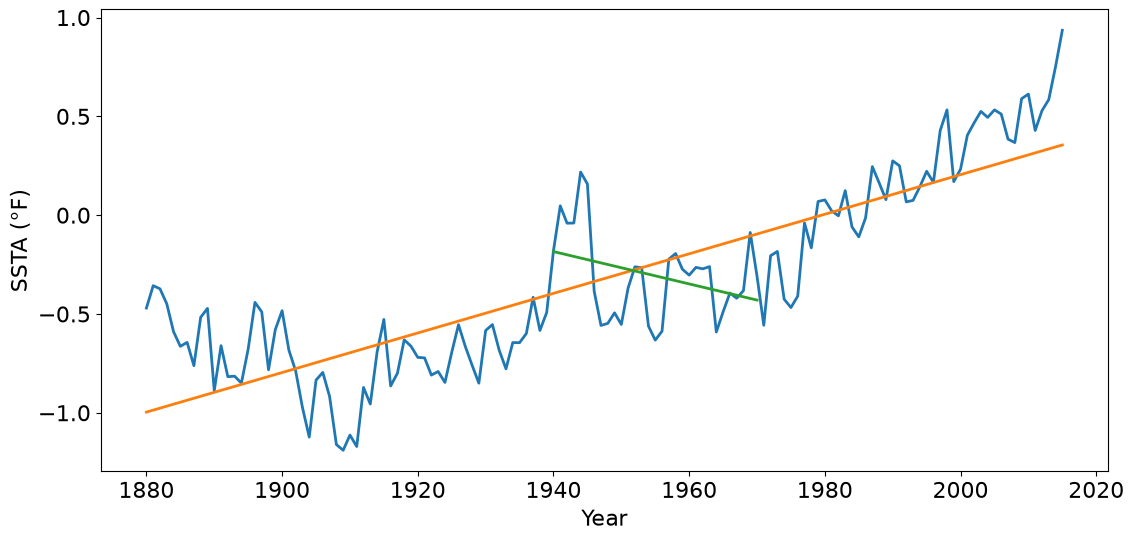

In [81]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"])
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept)
plt.plot(sst_ds.Year[60:91], sst_ds_1940_1970.slope*sst_ds.Year[60:91] + sst_ds_1940_1970.intercept)
plt.xlabel('Year')
plt.ylabel('SSTA ($\degree$F)')

**E.5** According to the internet, what might have caused this decline in SST during this perioud? Write a few sentances explaining this and cite your sources here.

According to Folland et al. (2018), potential facotrs contributing to this decline in SST are cooling effects from El Niño-Southern Oscillation (ENSO) and the Interdecadal Pacific Oscillation (IPO) combined with a decline in the Atlantic Multidecadal Oscillation (AMO) and increased volcanic gases and ash in the atmosphere. Mt. Agung erupted in 1963, contributing to this increased volancic contribution. All three of these oscillations go between states that favor overall cooling or warming driven by impacts to winds, air pressure, and circulation because of the sea surface temperature change.  

Full citation: Chris K. Folland et al., Causes of irregularities in trends of global mean surface temperature since the late 19th century.Sci. Adv.4,eaao5297(2018).DOI:10.1126/sciadv.aao5297


**E.6** Detrend from 1970 on and plot your result. Compare this to an ENSO (El Nino) index and speculate on what may have caused this interannual variability. How does ENSO affect SST and why?

Overall, the detrended data from 1970 onward follows the general pattern of the ENSO index from that timeframe. The ENSO oscillation usually occurs every 2 - 5 years and is likely a contributing factor to the observed global trends. During El Niño years of ENSO, SST increases in the region. This increased SST impacts weather patterns and influences spread of warmer water. 

In [82]:
sst_ds_1970_present = stats.linregress(sst_ds.Year[90:], sst_ds["Annual anomaly"][90:])

In [83]:
sst_ds_1970_present

LinregressResult(slope=np.float64(0.0231983908973173), intercept=np.float64(-46.03777006290472), rvalue=np.float64(0.9220490019048976), pvalue=np.float64(9.424068042507911e-20), stderr=np.float64(0.0014681505420044154), intercept_stderr=np.float64(2.9253548881084583))

In [96]:
# subset dataset for 1970 to present
sst_ds_1970 = sst_ds.isel(Year = slice(90, None))
sst_ds_1970

<xarray.Dataset> Size: 1kB
Dimensions:                        (Year: 46)
Coordinates:
  * Year                           (Year) int64 368B 1970 1971 ... 2014 2015
Data variables:
    Annual anomaly                 (Year) float64 368B -0.3086 ... 0.9356
    Lower 95% confidence interval  (Year) float64 368B -0.5433 ... 0.6401
    Upper 95% confidence interval  (Year) float64 368B -0.07395 ... 1.231

In [98]:
present_1970_trend = sst_ds_1970_present.slope*sst_ds_1970.Year + sst_ds_1970_present.intercept

In [186]:
sst_1970_detrended = sst_ds_1970["Annual anomaly"] - present_1970_trend

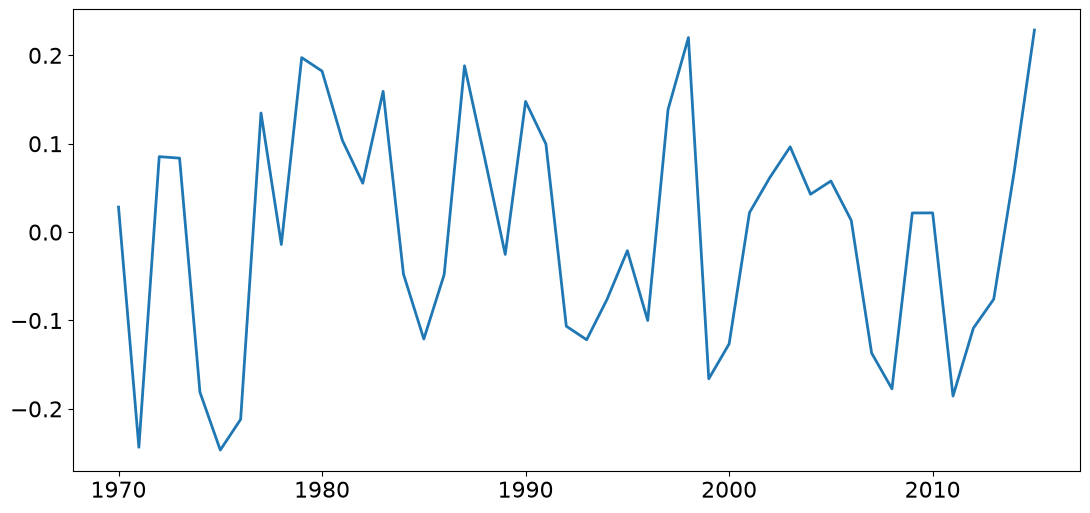

In [100]:
plt.plot(sst_ds_1970.Year, sst_1970_detrended)

In [ ]:
# ENSO data accessed from NOAA website
enso = pd.read_csv('RONI.ascii.txt', sep = r"\s+")
enso

,SEAS,YR,ANOM
0,DJF,1950,-1.19
1,JFM,1950,-1.08
2,FMA,1950,-0.96
3,MAM,1950,-1.00
4,AMJ,1950,-0.99
...,...,...,...
916,AMJ,2026,0.49
917,MJJ,2026,0.97
918,JJA,2026,1.36
919,JAS,2026,1.69


In [ ]:
# filter for just 1970 onward
enso_filter = enso[enso['YR'].between(1970, 2015)]
enso_filter

,SEAS,YR,ANOM
240,DJF,1970,0.46
241,JFM,1970,0.21
242,FMA,1970,0.24
243,MAM,1970,0.24
244,AMJ,1970,0.12
...,...,...,...
787,JAS,2015,1.54
788,ASO,2015,1.80
789,SON,2015,2.03
790,OND,2015,2.18


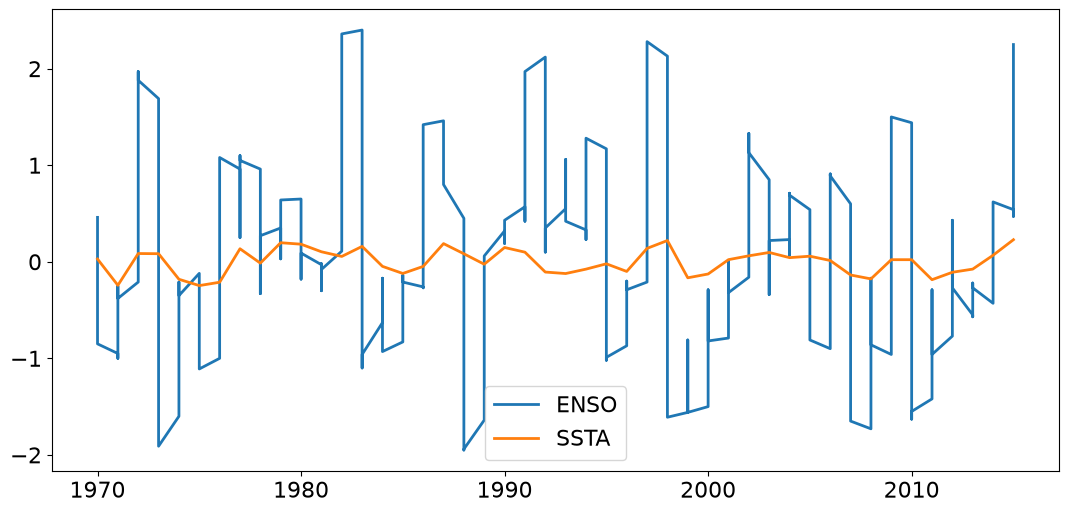

In [187]:
plt.plot(enso_filter['YR'], enso_filter['ANOM'], label = 'ENSO')
plt.plot(sst_ds_1970.Year, sst_1970_detrended, label = 'SSTA')
plt.legend()

**E.7** Perform a five year moving average of your detrended data from E.6. Explain your result in relation to the periodicity of ENSO.

Detrending data helps show trends by reducing some of the variability. What you see is a clearer pattern following the El Niño and La Niña years of the ENSO.

In [188]:
sst_1970_detrended

<xarray.DataArray (Year: 46)> Size: 368B
array([ 0.0283066 , -0.243434  ,  0.08537561,  0.08367102, -0.18104597,
       -0.24659476, -0.21187815,  0.13478206, -0.01404013,  0.19741308,
        0.18215269,  0.1037501 ,  0.0553391 ,  0.15929631, -0.04746788,
       -0.12095287, -0.04802586,  0.18820615,  0.08281256, -0.02523963,
        0.14781418,  0.09956699, -0.1064304 , -0.1218006 , -0.07617599,
       -0.02108698, -0.10002597,  0.13877644,  0.22010945, -0.16595274,
       -0.12650933,  0.02200868,  0.06173289,  0.0964729 ,  0.0428311 ,
        0.05778371,  0.01325352, -0.13679627, -0.17728726,  0.02164515,
        0.02172256, -0.18552043, -0.10869642, -0.07591661,  0.067466  ,
        0.2285894 ])
Coordinates:
  * Year     (Year) int64 368B 1970 1971 1972 1973 1974 ... 2012 2013 2014 2015

In [191]:
sst_rolling = np.zeros(46)

In [192]:

for i in range(42): 
    sst_rolling[i+2] = (sst_1970_detrended[i] + sst_1970_detrended[i+1] + sst_1970_detrended[i+2] + sst_1970_detrended[i+3] + sst_1970_detrended[i+4])/5

sst_rolling

array([ 0.        ,  0.        , -0.04542535, -0.10040562, -0.09409445,
       -0.08421316, -0.10375539, -0.02806358,  0.05768591,  0.12081156,
        0.10492297,  0.13959026,  0.09061406,  0.02999295, -0.00036224,
        0.02621117,  0.01091442,  0.01536007,  0.06911348,  0.09863205,
        0.03970474, -0.00121789, -0.01140516, -0.0451854 , -0.08510399,
       -0.03606262,  0.03231939,  0.01436404, -0.00672043,  0.0176865 ,
        0.00227779, -0.02244952,  0.01930725,  0.05616586,  0.05441482,
        0.01470899, -0.04004304, -0.04428023, -0.05149246, -0.09124725,
       -0.08562728, -0.06535315, -0.05618898, -0.01481561,  0.        ,
        0.        ])

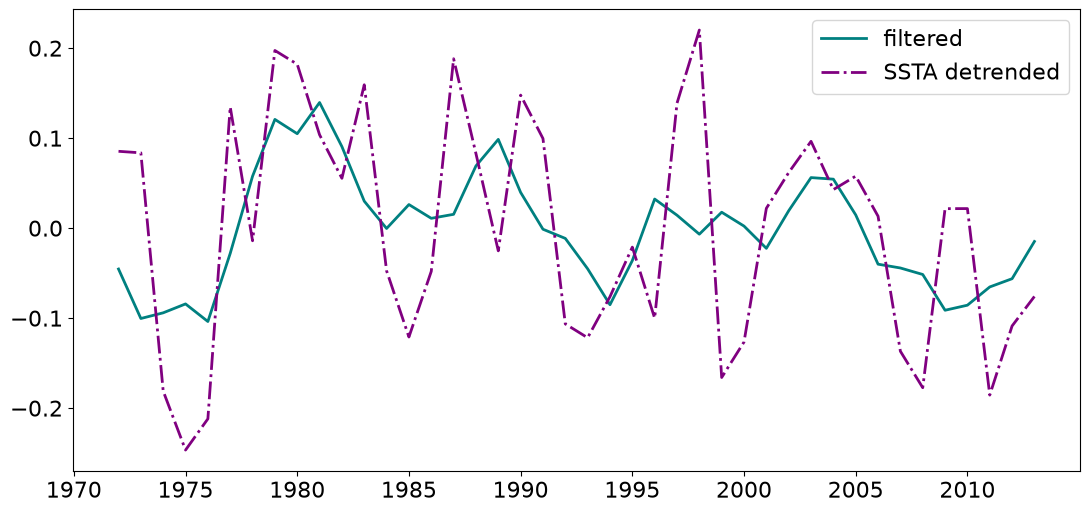

In [198]:
# skip last two years to line up with calculated averages
plt.plot(sst_ds.Year[92:-2],sst_rolling[2:-2], label = "filtered", color = 'teal')
plt.plot(sst_ds.Year[92:-2],sst_1970_detrended[2:-2], label = 'SSTA detrended', color = 'purple', linestyle = '-.')
plt.xticks(np.arange(1970, 2015, 5))
plt.legend()

**Notes** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

[Reference Notebook]('Reference_notebook.ipynb')